# Exercises week 42

**October 12–16, 2026**

Date: **Deadline is Friday October 16 at midnight**

# Overarching aims of the exercises this week

The aim of the exercises this week is to compute the gradient of the neural
network you implemented last week, and then to train it.

To train neural networks we use gradient descent, since there is no
analytical expression for the optimal parameters. This means that you need
the gradient of the cost function with respect to the network parameters,
and then a gradient method. The gradient is computed with the
**backpropagation algorithm**, Section [8.8](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#backpropagation) of the
lecture notes, which Monday's lecture derived and which you now write by
hand. At every step you check your result against `jax.grad`, which does the
same computation for you.

You will begin by computing the gradient of a network with one layer, then
two layers, then any number of layers. Keeping track of the shapes and doing
things step by step will be very important this week.

Exercises 2–5 use the **single-vector convention** of exercises 1–4 of last
week: one input vector at a time, weights of shape (outputs, inputs) and
$z = Wx + b$. Exercise 6 switches to the **batched convention** of the lecture
notes (samples in rows, weights of shape (inputs, outputs), $Z = XW + b$,
Eq. (8.21)), which is what you need for Project 2. If you did not finish
last week's set, the full solution is in `exercisesweek41_solutions.ipynb`.

We recommend that you do the exercises by editing and running this notebook,
as it includes some checks along the way that you have implemented the
pieces correctly, and running small parts of the code at a time is important
for understanding the methods. If you cannot run the notebook locally, Google
Colab works as well, though we recommend that you set up VSCode (or
JupyterLab) and your Python environment to run code like this on your own
machine; ask on the course Discord or at the lab sessions if you have
trouble.

First, some setup code that you will need; don't change this cell. As last
week, the activation and cost functions are written with `jax.numpy`
(`jnp`) so that JAX can differentiate them. The derivatives `ReLU_der` and
`sigmoid_der` are the ones you will use in your own backpropagation.

In [1]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    # numpy-compatible functions that JAX can differentiate
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

np.random.seed(2026)   # so that your numbers can be compared with those of other students


# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)


# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)


def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))


def mse(predict, target):
    return jnp.mean((predict - target) ** 2)

# Exercise 1 - Understand the feed forward pass

**a)** Complete last week's exercises if you haven't already (recommended),
and compare with `exercisesweek41_solutions.ipynb`. In particular make sure
you understand the shapes of `W`, `b`, `z` and `a` in the two conventions
(single vector and batched), since every gradient below has the shape of the
parameter it belongs to.

**Answer:** In the single-vector convention a layer is $z = Wx + b$ with `W` of shape
(outputs, inputs), `x` of shape (inputs,) and `b`, `z`, `a` of shape (outputs,).
In the batched convention $Z = XW + b$ with `X` of shape (n_samples, inputs),
`W` of shape (inputs, outputs), `b` of shape (outputs,) (broadcast over the rows) and
`Z`, `A` of shape (n_samples, outputs). The batched `W` is the transpose of the
single-vector `W`, so that the samples stay in the rows all the way through the network.

# Exercise 2 - Gradient with one layer using JAX

For the first few exercises we will not use batched inputs. Only a single
input vector is passed through the layer at a time.

In this exercise you will compute the gradient of a single layer. You only
need to change the code in the cells right below an exercise; the rest works
out of the box. Feel free to make changes and see how things work, though!

**a)** If the weights and bias of a layer have shapes (10, 4) and (10,),
what will the shapes of the gradients of the cost function with respect to
these weights and this bias be?

**Answer:** The cost is a scalar, so its gradient with respect to an array has the same
shape as that array: $\partial C/\partial W$ has shape (10, 4) and
$\partial C/\partial b$ has shape (10,), one number per parameter.

**b)** Complete the `feed_forward_one_layer` function. It should use the
sigmoid activation function. Also define the weight and bias with the
correct shapes.

In [2]:
rng = np.random.default_rng(2026)
def feed_forward_one_layer(W, b, x):
    z = W @ x + b
    a = sigmoid(z)
    return a


def cost_one_layer(W, b, x, target):
    predict = feed_forward_one_layer(W, b, x)
    return mse(predict, target)


x = np.random.rand(2)
target = np.random.rand(3)

W = rng.normal(0, 1/np.sqrt(3), (3, 2))
b = np.zeros(3) + 0.01

**c)** Compute the gradient of the cost function with respect to the weight
and bias by running the cell below. You will not need to change anything,
just make sure it runs by defining things correctly in the cell above.
`jax.grad(cost_one_layer, argnums=(0, 1))` returns a function that computes
the gradient of `cost_one_layer` with respect to its first two arguments,
`W` and `b`, by reverse-mode automatic differentiation — which for a neural
network *is* backpropagation (Section 4.14 of the lecture notes).

In [3]:
jax_one_layer = jax.grad(cost_one_layer, argnums=(0, 1))
W_g, b_g = jax_one_layer(W, b, x, target)
print(W_g, b_g)

[[-0.01772207 -0.03336935]
 [ 0.01592443  0.02998454]
 [ 0.0009507   0.00179009]] [-0.08079517  0.07259972  0.00433424]


# Exercise 3 - Gradient with one layer writing backpropagation by hand

Before you use the gradient you found using JAX, you will have to find the
gradient "manually", to better understand how the backpropagation
computation works. To do backpropagation "manually", you will need to write
out expressions for many derivatives along the computation. This is the
scalar/one-layer case of Section
[8.8.1](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#two-scalar-examples-no-hidden-layer-and-one-hidden-layer)
of the lecture notes, now with vectors.

We want to find the gradient of the cost function with respect to the weight
and bias. This is quite hard to do directly, so we instead use the chain rule
to combine multiple derivatives which are easier to compute.

$$
\frac{dC}{dW} = \frac{dC}{da}\frac{da}{dz}\frac{dz}{dW}
$$

$$
\frac{dC}{db} = \frac{dC}{da}\frac{da}{dz}\frac{dz}{db}
$$

**a)** Which intermediary results can be reused between the two expressions?

**Answer:** The product $\frac{dC}{da}\frac{da}{dz} = \frac{dC}{dz}$ (the error $\delta$ of the
layer) appears in both expressions, so it is computed once and reused.
Only the last factor, $dz/dW$ or $dz/db$, differs.

**b)** What is the derivative of the cost with respect to the final
activation? You can use the JAX calculation to make sure you get the correct
result. Remember that we compute the *mean* in `mse`.

**Answer:** With $C = \frac{1}{n}\sum_i (a_i - y_i)^2$ we get
$\frac{\partial C}{\partial a_i} = \frac{2}{n}(a_i - y_i)$, where $n$ is the number of
elements in the prediction.

In [4]:
z = W @ x + b
a = sigmoid(z)

predict = a


def mse_der(predict, target):
    return 2.0*(predict-target)/predict.size


print(mse_der(predict, target))

cost_jax = jax.grad(mse, argnums=0)
print(cost_jax(predict, target))

[-0.32326909  0.29116493  0.01733892]
[-0.32326909  0.29116493  0.01733892]


**c)** What is the expression for the derivative of the sigmoid activation
function? You can use the JAX calculation to make sure you get the correct
result. (Since the sigmoid acts element by element, the gradient of
`sum(sigmoid(z))` with respect to `z` is exactly the element-wise derivative
$\sigma'(z)$; that is what the JAX line below computes.)

**Answer:** $\sigma'(z) = \sigma(z)\,(1-\sigma(z))$, applied element-wise.

In [5]:
def sigmoid_der(z):
    s=sigmoid(z)
    return s*(1.0-s)


print(sigmoid_der(z))

sigmoid_jax = jax.grad(lambda z: jnp.sum(sigmoid(z)))   # element-wise derivative of an element-wise function
print(sigmoid_jax(z))

[0.24993164 0.24934226 0.24997193]
[0.24993164 0.24934226 0.24997193]


**d)** Using the two derivatives you just computed, compute this
intermediary gradient you will use later (it is the *error* $\delta$ of the
layer, Eq. (8.60) of the lecture notes):

$$
\frac{dC}{dz} = \frac{dC}{da}\frac{da}{dz}
$$

In [6]:
dC_da = mse_der(a, target)
dC_dz = dC_da * sigmoid_der(z)   # element-wise
print(dC_dz)

[-0.08079517  0.07259972  0.00433424]


**e)** What is the derivative of the intermediary `z` with respect to the
weight and bias? What should the shapes be? The one for the weights is a
little tricky; it can be easier to play around in the next exercise first.
You can also try computing it with JAX to get a hint. (Lecture notes:
Eqs. (8.61)–(8.63), "the error is the bias gradient", and the outer product
with the layer input for the weights.)

**Answer:** $z_i = \sum_k W_{ik}x_k + b_i$, so

* $\partial z_i/\partial b_j = \delta_{ij}$, i.e. $dz/db$ is the identity matrix, and
  $dC/db = dC/dz$, shape (3,).
* $\partial z_i/\partial W_{jk} = \delta_{ij}\,x_k$. Contracting with $dC/dz$ gives
  $\frac{\partial C}{\partial W_{jk}} = \frac{\partial C}{\partial z_j}x_k$, i.e. the outer product
  $dC/dW = \delta\, x^T$ = `np.outer(dC_dz, x)`, with shape (3, 2), the same as `W`.

The full derivative $dz/dW$ is a 3-index object of shape (3, 3, 2), but we never need to
build it, since it is only an identity times $x$.

In [7]:

dz_dW = jax.jacobian(lambda W: W @ x + b)(W)
dz_db = jax.jacobian(lambda b: W @ x + b)(b)
print("dz/dW shape:", dz_dW.shape)
print("dz/db =\n", dz_db)

dz/dW shape: (3, 3, 2)
dz/db =
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


**f)** Now combine the expressions you have worked with so far to compute
the gradients! Note that you always need to do a feed forward pass while
saving the `z`s and `a`s before you do backpropagation, as they are used in
the derivative expressions.

In [8]:
z = W @ x + b
a = sigmoid(z)

dC_da = mse_der(a, target)
dC_dz = dC_da * sigmoid_der(z)
dC_dW = np.outer(dC_dz, x)
dC_db = dC_dz

print(dC_dW, dC_db)

[[-0.01772207 -0.03336935]
 [ 0.01592443  0.02998454]
 [ 0.0009507   0.00179009]] [-0.08079517  0.07259972  0.00433424]


You should get the same results as with JAX.

In [9]:
W_g, b_g = jax_one_layer(W, b, x, target)
print(W_g, b_g)
print(np.allclose(dC_dW, W_g), np.allclose(dC_db, b_g))

[[-0.01772207 -0.03336935]
 [ 0.01592443  0.02998454]
 [ 0.0009507   0.00179009]] [-0.08079517  0.07259972  0.00433424]
True True


# Exercise 4 - Gradient with two layers writing backpropagation by hand

Now that you have implemented backpropagation for one layer, you have found
most of the expressions you will need for more layers. Let's move up to two
layers (compare with the two-layer network of Section
[8.8.2](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#two-inputs-two-hidden-nodes-one-output) of the lecture
notes).

In [10]:
x = np.random.rand(2)
target = np.random.rand(4)

W1 = np.random.rand(3, 2)
b1 = np.random.rand(3)

W2 = np.random.rand(4, 3)
b2 = np.random.rand(4)

layers = [(W1, b1), (W2, b2)]

In [11]:
z1 = W1 @ x + b1
a1 = sigmoid(z1)
z2 = W2 @ a1 + b2
a2 = sigmoid(z2)

We begin by computing the gradients of the last layer, as the gradients
must be propagated backwards from the end.

**a)** Compute the gradients of the last layer, just like you did for the
single layer in the previous exercise.

In [12]:
dC_da2 = mse_der(a2, target)
dC_dz2 = dC_da2 * sigmoid_der(z2)
dC_dW2 = np.outer(dC_dz2, a1)    
dC_db2 = dC_dz2

To find the derivative of the cost with respect to the activation of the
first layer, we need a new expression, the one furthest to the right in the
following.

$$
\frac{dC}{da_1} = \frac{dC}{dz_2}\frac{dz_2}{da_1}
$$

**b)** What is the derivative of the second-layer intermediary with respect
to the first-layer activation? (First recall how you compute $z_2$.) This is
the step that *propagates the error backwards*, Eq. (8.64) of the lecture
notes.

$$
\frac{dz_2}{da_1}
$$

**Answer:** Since $z_2 = W_2 a_1 + b_2$, the derivative is $\frac{dz_2}{da_1} = W_2$
(shape (4, 3)). Contracting with $dC/dz_2$ (shape (4,)) over the output index gives
$\frac{dC}{da_1} = W_2^T \frac{dC}{dz_2}$, shape (3,).

In [13]:
dz2_da1 = W2
print(dz2_da1.shape)
#Check with jax
print(np.allclose(jax.jacobian(lambda a: W2 @ a + b2)(a1), dz2_da1))

(4, 3)
True


**c)** Use this expression, together with expressions which are equivalent
to the ones for the last layer, to compute all the derivatives of the first
layer.

$$
\frac{dC}{dW_1} = \frac{dC}{da_1}\frac{da_1}{dz_1}\frac{dz_1}{dW_1}
$$

$$
\frac{dC}{db_1} = \frac{dC}{da_1}\frac{da_1}{dz_1}\frac{dz_1}{db_1}
$$

In [14]:
dC_da1 = W2.T @ dC_dz2
dC_dz1 = dC_da1 * sigmoid_der(z1)
dC_dW1 = np.outer(dC_dz1, x)
dC_db1 = dC_dz1

In [15]:
print(dC_dW1, dC_db1)
print(dC_dW2, dC_db2)

[[0.00559457 0.00112249]
 [0.00327166 0.00065642]
 [0.00365777 0.00073389]] [0.0056651  0.00331291 0.00370388]
[[-0.01575975 -0.01887663 -0.0185016 ]
 [ 0.01224558  0.01466745  0.01437605]
 [-0.00723854 -0.00867014 -0.00849789]
 [ 0.01779889  0.02131906  0.02089551]] [-0.02273764  0.01766752 -0.01044352  0.02567964]


**d)** Make sure you got the same gradient as the following code, which
uses JAX to do backpropagation. (`jax.grad` accepts a list of tuples of
arrays as the argument to differentiate and returns a gradient with the
same structure.)

In [16]:
def feed_forward_two_layers(layers, x):
    W1, b1 = layers[0]
    z1 = W1 @ x + b1
    a1 = sigmoid(z1)

    W2, b2 = layers[1]
    z2 = W2 @ a1 + b2
    a2 = sigmoid(z2)

    return a2

In [17]:
def cost_two_layers(layers, x, target):
    predict = feed_forward_two_layers(layers, x)
    return mse(predict, target)


grad_two_layers = jax.grad(cost_two_layers, argnums=0)
grad_two_layers(layers, x, target)

[(Array([[0.00559457, 0.00112249],
         [0.00327166, 0.00065642],
         [0.00365777, 0.00073389]], dtype=float64),
  Array([0.0056651 , 0.00331291, 0.00370388], dtype=float64)),
 (Array([[-0.01575975, -0.01887663, -0.0185016 ],
         [ 0.01224558,  0.01466745,  0.01437605],
         [-0.00723854, -0.00867014, -0.00849789],
         [ 0.01779889,  0.02131906,  0.02089551]], dtype=float64),
  Array([-0.02273764,  0.01766752, -0.01044352,  0.02567964], dtype=float64))]

In [18]:
(W1_g, b1_g), (W2_g, b2_g) = grad_two_layers(layers, x, target)
print(np.allclose(dC_dW1, W1_g), np.allclose(dC_db1, b1_g),
      np.allclose(dC_dW2, W2_g), np.allclose(dC_db2, b2_g))

True True True True


**e)** How would you use the gradient from this layer to compute the
gradient of an even earlier layer? Would the expressions be any different?

**Answer:** Exactly the same way: from $dC/dz_1$ we get $dC/da_0 = W_1^T\, dC/dz_1$, then
$dC/dz_0 = dC/da_0 \odot f_0'(z_0)$, $dC/dW_0 = $ `np.outer(dC_dz0, x)` and
$dC/db_0 = dC/dz_0$. The expressions are identical for every hidden layer; only the
last layer is special, because there $dC/da$ comes directly from the cost function. This
is what makes a loop over the layers (Exercise 5) possible.

# Exercise 5 - Gradient with any number of layers writing backpropagation by hand

Well done on getting this far! Now it's time to compute the gradient with
any number of layers: the four equations of backpropagation, Section
[8.8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-four-equations-of-backpropagation), and the
algorithm of Section [8.8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-algorithm).

First, some code from the general neural network code from last week. Note
that we are still sending in one input vector at a time. We will change it to
use batched inputs later.

In [19]:
def create_layers(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(layer_output_size, i_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers


def feed_forward(input, layers, activation_funcs):
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = W @ a + b
        a = activation_func(z)
    return a


def cost(layers, input, activation_funcs, target):
    predict = feed_forward(input, layers, activation_funcs)
    return mse(predict, target)

You might already have noticed a very important detail in backpropagation:
you need the values from the forward pass to compute all the gradients! The
feed forward function above is great for efficiency and for using JAX, as it
only cares about computing the final output, but now we need to also save
the results along the way.

Here is a function which does that for you.

In [20]:
def feed_forward_saver(input, layers, activation_funcs):
    layer_inputs = []
    zs = []
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = W @ a + b
        a = activation_func(z)

        zs.append(z)

    return layer_inputs, zs, a

**a)** Now complete the backpropagation function so that it returns the
gradient of the cost function with respect to all the weights and biases.
Use the JAX calculation below to make sure you get the correct answer.

In [21]:
def backpropagation(
    input, layers, activation_funcs, target, activation_ders, cost_der=mse_der
):
    layer_inputs, zs, predict = feed_forward_saver(input, layers, activation_funcs)

    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # For last layer we use cost derivative as dC_da(L) can be computed directly
            dC_da = cost_der(predict, target)
        else:
            # For other layers we build on previous z derivative, as dC_da(i) = dC_dz(i+1) * dz(i+1)_da(i)
            (W, b) = layers[i + 1]
            dC_da = W.T @ dC_dz

        dC_dz = dC_da * activation_der(z)
        dC_dW = np.outer(dC_dz, layer_input)
        dC_db = dC_dz

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads

In [22]:
network_input_size = 2
layer_output_sizes = [3, 4]
activation_funcs = [sigmoid, ReLU]
activation_ders = [sigmoid_der, ReLU_der]

layers = create_layers(network_input_size, layer_output_sizes)

x = np.random.rand(network_input_size)
target = np.random.rand(4)

In [23]:
layer_grads = backpropagation(x, layers, activation_funcs, target, activation_ders)
print(layer_grads)

[(array([[ 0.00226932,  0.0015674 ],
       [ 0.00477115,  0.00329538],
       [-0.00015473, -0.00010687]]), Array([ 0.00424936,  0.00893407, -0.00028974], dtype=float64)), (array([[ 0.02283418,  0.00923438,  0.03226744],
       [-0.06580509, -0.02661226, -0.0929905 ],
       [-0.        , -0.        , -0.        ],
       [-0.        , -0.        , -0.        ]]), Array([ 0.04165045, -0.12003109, -0.        , -0.        ], dtype=float64))]


In [24]:
cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, x, [sigmoid, ReLU], target)
print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

[(Array([[ 0.00226932,  0.0015674 ],
       [ 0.00477115,  0.00329538],
       [-0.00015473, -0.00010687]], dtype=float64), Array([ 0.00424936,  0.00893407, -0.00028974], dtype=float64)), (Array([[ 0.02283418,  0.00923438,  0.03226744],
       [-0.06580509, -0.02661226, -0.0929905 ],
       [ 0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ]], dtype=float64), Array([ 0.04165045, -0.12003109,  0.        ,  0.        ], dtype=float64))]
[(True, True), (True, True)]


As an extra check, a deeper network with other activations:

In [25]:
layers_deep = create_layers(5, [7, 6, 4, 2])
funcs_deep = [ReLU, sigmoid, ReLU, sigmoid]
ders_deep = [ReLU_der, sigmoid_der, ReLU_der, sigmoid_der]
x_deep = np.random.rand(5)
t_deep = np.random.rand(2)

g_hand = backpropagation(x_deep, layers_deep, funcs_deep, t_deep, ders_deep)
g_jax = jax.grad(cost, argnums=0)(layers_deep, x_deep, funcs_deep, t_deep)
print(all(np.allclose(dW, dWj) and np.allclose(db, dbj)
          for (dW, db), (dWj, dbj) in zip(g_hand, g_jax)))

True


# Exercise 6 - Batched inputs

Make new versions of all the functions in exercise 5 which now take batched
inputs instead. See last week's exercise 5 (and its solution) for details on
how to batch inputs to neural networks: samples in the rows of `inputs`,
weights of shape (inputs, outputs), `z = a @ W + b`. You will also need to
update the backpropagation function. Two things change there: the error is
propagated with `dC_dz @ W.T` instead of `W.T @ dC_dz`, and the gradients
of the weights and biases are *sums over the samples*,
`dC_dW = layer_input.T @ dC_dz` and `dC_db = np.sum(dC_dz, axis=0)` — compare
Eqs. (8.65)–(8.68) of the lecture notes written for a batch. Check your
batched backpropagation against `jax.grad` of the batched cost, as above.

In [26]:
def create_layers_batch(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(i_size, layer_output_size)   # (inputs, outputs)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers


def feed_forward_batch(inputs, layers, activation_funcs):
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = a @ W + b
        a = activation_func(z)
    return a


def cost_batch(layers, inputs, activation_funcs, targets):
    predict = feed_forward_batch(inputs, layers, activation_funcs)
    return mse(predict, targets)


def feed_forward_saver_batch(inputs, layers, activation_funcs):
    layer_inputs = []
    zs = []
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation_func(z)

        zs.append(z)

    return layer_inputs, zs, a


def backpropagation_batch(
    input, layers, activation_funcs, target, activation_ders, cost_der=mse_der
):
    layer_inputs, zs, predict = feed_forward_saver_batch(input, layers, activation_funcs)

    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # For last layer we use cost derivative as dC_da(L) can be computed directly
            dC_da = cost_der(predict, target)
        else:
            # For other layers we build on previous z derivative, as dC_da(i) = dC_dz(i+1) * dz(i+1)_da(i)
            (W, b) = layers[i + 1]
            dC_da =   dC_dz@ W.T

        dC_dz = dC_da * activation_der(z) 
        dC_dW = layer_input.T @ dC_dz
        dC_db = np.sum(dC_dz, axis=0)

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads



Note that `mse_der` divides by `predict.size` $= n_\text{samples}\cdot n_\text{outputs}$,
which is exactly the normalisation of `mse` on a batch (it takes the mean over all elements),
so the same `mse_der` works unchanged.

In [27]:
network_input_size = 2
layer_output_sizes = [3, 4]
activation_funcs = [sigmoid, ReLU]
activation_ders = [sigmoid_der, ReLU_der]

layers = create_layers_batch(network_input_size, layer_output_sizes)

n_samples = 5
X = np.random.rand(n_samples, network_input_size)
Y = np.random.rand(n_samples, 4)

layer_grads = backpropagation_batch(X, layers, activation_funcs, Y, activation_ders)
layer_grads_jax = jax.grad(cost_batch, argnums=0)(layers, X, activation_funcs, Y)

for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax):
    print(dW.shape, db.shape, np.allclose(dW, dW_j), np.allclose(db, db_j))

(2, 3) (3,) True True
(3, 4) (4,) True True


# Exercise 7 - Training

**a)** Complete exercises 6 and 7 from last week (the iris data, softmax
output and cross entropy), but use your own backpropagation implementation
to compute the gradient.
- IMPORTANT: Do not implement the derivative terms for the softmax and the
  cross entropy separately, it will be very hard!
- Instead, use the fact that the derivatives multiplied together simplify to
  **prediction − target**: for the softmax output with the cross entropy the
  error of the last layer is $\delta^L = a^L - y$, Eq. (8.69) of the lecture
  notes (derived in Section [5.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter5.html) for the softmax; see also
  [this derivation](https://shivammehta25.github.io/posts/deriving-categorical-cross-entropy-and-softmax/)).
  In your `backpropagation` function this means that for the last layer you
  set `dC_dz = predict - target` directly, skipping `cost_der` and
  `activation_der`.

**b)** Use stochastic gradient descent with momentum when you train your
network (Sections [4.6 and 4.7](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter4.html) of the lecture notes; reuse
your Project 1 code). Call the learning rate `gamma`, as everywhere else in
the course, and compare the accuracy on a test set with that of the
full-batch gradient descent of last week.

### The data, the softmax and the cross entropy (from last week)

We split the iris data into a training and a test set, and scale the features
(using the mean and standard deviation of the training set only).

In [28]:
from sklearn.model_selection import train_test_split

iris = datasets.load_iris()
inputs = iris.data

# one-hot targets
targets = np.zeros((len(iris.data), 3))
for i, t in enumerate(iris.target):
    targets[i, t] = 1


def accuracy(predictions, targets):
    return accuracy_score(np.argmax(targets, axis=1), np.argmax(predictions, axis=1))


def softmax(z):
    """Softmax of each row of z (batched input)."""
    e_z = jnp.exp(z - jnp.max(z, axis=1, keepdims=True))
    return e_z / jnp.sum(e_z, axis=1, keepdims=True)


def cross_entropy(predict, target):
    """Multiclass cross entropy, averaged over the samples."""
    return -jnp.mean(jnp.sum(target * jnp.log(predict), axis=1))


def cost_ce(layers, inputs, activation_funcs, targets):
    return cross_entropy(feed_forward_batch(inputs, layers, activation_funcs), targets)


X_train, X_test, y_train, y_test = train_test_split(
    inputs, targets, test_size=0.2, random_state=2026, stratify=iris.target
)
mean, std = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std
print(X_train.shape, X_test.shape)

(120, 4) (30, 4)


### Backpropagation with softmax output and cross entropy

For the last layer we use $\delta^L = \partial C/\partial z^L = (a^L - y)/n$ directly,
skipping `cost_der` and `activation_der`. The factor $1/n$ is there because our
cross entropy takes the *mean* over the $n$ samples of the batch.

In [29]:
def backpropagation_softmax_ce(inputs, layers, activation_funcs, targets, activation_ders):
    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)
    n = inputs.shape[0]

    layer_grads = [() for layer in layers]

    for i in reversed(range(len(layers))):
        layer_input, z = layer_inputs[i], zs[i]

        if i == len(layers) - 1:
            dC_dz = (predict - targets) / n       # softmax + cross entropy, Eq. (8.69)
        else:
            (W, b) = layers[i + 1]
            dC_da = dC_dz @ W.T
            dC_dz = dC_da * activation_ders[i](z)

        dC_dW = layer_input.T @ dC_dz
        dC_db = np.sum(dC_dz, axis=0)

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads


# check against JAX
activation_funcs = [sigmoid, softmax]
activation_ders = [sigmoid_der, None]      # the softmax derivative is never used
layers = create_layers_batch(4, [8, 3])

g_hand = backpropagation_softmax_ce(X_train, layers, activation_funcs, y_train, activation_ders)
g_jax = jax.grad(cost_ce, argnums=0)(layers, X_train, activation_funcs, y_train)
print([(np.allclose(dW, dWj), np.allclose(db, dbj)) for (dW, db), (dWj, dbj) in zip(g_hand, g_jax)])

[(True, True), (True, True)]


### a) Full-batch gradient descent with our own backpropagation

This is last week's training loop, but with the gradient from `backpropagation_softmax_ce`
instead of `jax.grad`.

In [30]:
def copy_layers(layers):
    return [(W.copy(), b.copy()) for W, b in layers]


def train_gd(X, y, layers, activation_funcs, activation_ders, gamma=0.1, epochs=500):
    layers = copy_layers(layers)
    history = []
    for epoch in range(epochs):
        layer_grads = backpropagation_softmax_ce(X, layers, activation_funcs, y, activation_ders)
        layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, layer_grads)]
        history.append(float(cost_ce(layers, X, activation_funcs, y)))
    return layers, history


np.random.seed(2026)
activation_funcs = [sigmoid, softmax]
activation_ders = [sigmoid_der, None]
layers_init = create_layers_batch(4, [8, 3])

print("Before training: train acc = %.3f, test acc = %.3f" % (
    accuracy(feed_forward_batch(X_train, layers_init, activation_funcs), y_train),
    accuracy(feed_forward_batch(X_test, layers_init, activation_funcs), y_test)))

layers_gd, hist_gd = train_gd(X_train, y_train, layers_init, activation_funcs, activation_ders,
                              gamma=0.1, epochs=500)

print("Full-batch GD:   train acc = %.3f, test acc = %.3f" % (
    accuracy(feed_forward_batch(X_train, layers_gd, activation_funcs), y_train),
    accuracy(feed_forward_batch(X_test, layers_gd, activation_funcs), y_test)))

Before training: train acc = 0.333, test acc = 0.333
Full-batch GD:   train acc = 0.950, test acc = 0.967


### b) Stochastic gradient descent with momentum

For each epoch we shuffle the training data and split it into minibatches. For each
minibatch we compute the gradient $g$ with our backpropagation and update every
parameter $\theta$ with momentum,

$$
v \leftarrow \beta v + \gamma g, \qquad \theta \leftarrow \theta - v,
$$

where $\gamma$ is the learning rate and $\beta$ the momentum parameter.

In [31]:
def train_sgd_momentum(X, y, layers, activation_funcs, activation_ders,
                       gamma=0.1, beta=0.9, epochs=500, batch_size=16, seed=2026):
    rng = np.random.default_rng(seed)
    layers = copy_layers(layers)
    velocity = [(np.zeros_like(W), np.zeros_like(b)) for W, b in layers]
    n = X.shape[0]
    history = []

    for epoch in range(epochs):
        perm = rng.permutation(n)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            layer_grads = backpropagation_softmax_ce(X[idx], layers, activation_funcs, y[idx], activation_ders)

            velocity = [(beta * vW + gamma * dW, beta * vb + gamma * db)
                        for (vW, vb), (dW, db) in zip(velocity, layer_grads)]
            layers = [(W - vW, b - vb) for (W, b), (vW, vb) in zip(layers, velocity)]

        history.append(float(cost_ce(layers, X, activation_funcs, y)))
    return layers, history


layers_sgd, hist_sgd = train_sgd_momentum(X_train, y_train, layers_init, activation_funcs, activation_ders,
                                          gamma=0.1, beta=0.9, epochs=500, batch_size=16)

print("SGD + momentum:  train acc = %.3f, test acc = %.3f" % (
    accuracy(feed_forward_batch(X_train, layers_sgd, activation_funcs), y_train),
    accuracy(feed_forward_batch(X_test, layers_sgd, activation_funcs), y_test)))

SGD + momentum:  train acc = 0.992, test acc = 0.933


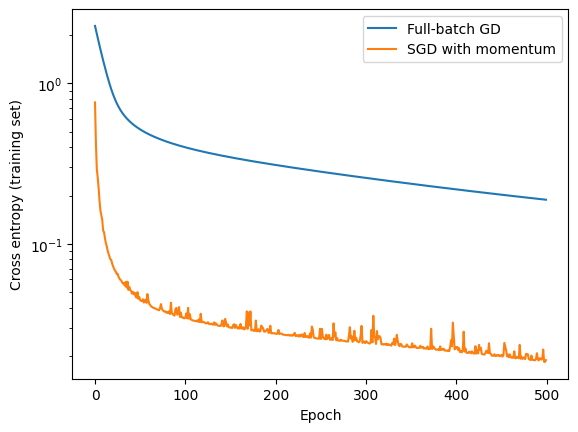

In [32]:
fig, ax = plt.subplots()
ax.semilogy(hist_gd, label="Full-batch GD")
ax.semilogy(hist_sgd, label="SGD with momentum")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross entropy (training set)")
ax.legend()
plt.show()

To make the comparison fairer we also look at the test accuracy as a function of the
number of epochs for both methods (same initial weights, same learning rate):

In [33]:
for epochs in [5, 20, 50, 200]:
    l_gd, _ = train_gd(X_train, y_train, layers_init, activation_funcs, activation_ders,
                       gamma=0.1, epochs=epochs)
    l_sgd, _ = train_sgd_momentum(X_train, y_train, layers_init, activation_funcs, activation_ders,
                                  gamma=0.1, beta=0.9, epochs=epochs, batch_size=16)
    print("epochs = %3d:  GD test acc = %.3f,  SGD+momentum test acc = %.3f" % (
        epochs,
        accuracy(feed_forward_batch(X_test, l_gd, activation_funcs), y_test),
        accuracy(feed_forward_batch(X_test, l_sgd, activation_funcs), y_test)))

epochs =   5:  GD test acc = 0.333,  SGD+momentum test acc = 0.933
epochs =  20:  GD test acc = 0.467,  SGD+momentum test acc = 0.967
epochs =  50:  GD test acc = 0.867,  SGD+momentum test acc = 0.967
epochs = 200:  GD test acc = 0.933,  SGD+momentum test acc = 0.933


**Comment:** Both methods end up with a high test accuracy on the iris data (it is an
easy data set, and the test set has only 30 flowers, so one misclassified flower changes the
accuracy by 0.033). The difference is in how fast they get there: with batch size 16 SGD
makes 8 parameter updates per epoch instead of 1, and momentum accumulates the steps
in consistent directions, so SGD with momentum reaches a low training cost after far fewer
epochs than full-batch gradient descent with the same $\gamma$. Full-batch GD needs many
more epochs (or a larger learning rate) to reach the same cost. With many epochs SGD with
momentum drives the training cost very low, which can lead to some overfitting.

# Exercise 8 (Optional) - Object orientation

Passing in the layers, activation functions, activation derivatives and cost
derivatives into the functions each time leads to code which is easy to
understand in isolation, but messier when used in a larger context with data
splitting, data scaling, gradient methods and so forth. Creating an object
which stores these values can lead to code which is much easier to use, and
is what we recommend for Project 2.

**a)** Write a neural network class. You are free to implement it how you
see fit, though we strongly recommend not to save any input or output values
as class attributes, nor to let the neural network class handle gradient
methods internally. Gradient methods should be handled outside, by
performing general operations on the `layer_grads` list using functions or
classes separate from the neural network.

We provide here a skeleton structure which should get you started.

In [ ]:
class NeuralNetwork:
    def __init__(
        self,
        network_input_size,
        layer_output_sizes,
        activation_funcs,
        activation_ders,
        cost_fun,
        cost_der,
        seed=None,
    ):
        rng = np.random.default_rng(seed)
        self.activation_funcs = activation_funcs
        self.activation_ders = activation_ders
        self.cost_fun = cost_fun
        self.cost_der = cost_der   # None means softmax + cross entropy

        self.layers = []
        i_size = network_input_size
        for o_size in layer_output_sizes:
            W = rng.normal(0, 1 / np.sqrt(i_size), (i_size, o_size))
            b = np.zeros(o_size) + 0.01
            self.layers.append((W, b))
            i_size = o_size

    def predict(self, inputs):
        # Simple feed forward pass
        return self.jax_compliant_predict(self.layers, inputs)

    def cost(self, inputs, targets):
        return self.cost_fun(self.predict(inputs), targets)

    def _feed_forward_saver(self, inputs):
        layer_inputs, zs = [], []
        a = inputs
        for (W, b), f in zip(self.layers, self.activation_funcs):
            layer_inputs.append(a)
            z = a @ W + b
            a = f(z)
            zs.append(z)
        return layer_inputs, zs, a

    def compute_gradient(self, inputs, targets):
        layer_inputs, zs, predict = self._feed_forward_saver(inputs)
        layer_grads = [() for _ in self.layers]

        for i in reversed(range(len(self.layers))):
            if i == len(self.layers) - 1:
                if self.cost_der is None:
                    dC_dz = (predict - targets) / inputs.shape[0]
                else:
                    dC_dz = self.cost_der(predict, targets) * self.activation_ders[i](zs[i])
            else:
                W_next, _ = self.layers[i + 1]
                dC_dz = (dC_dz @ W_next.T) * self.activation_ders[i](zs[i])

            layer_grads[i] = (layer_inputs[i].T @ dC_dz, np.sum(dC_dz, axis=0))
        return layer_grads

    def update_weights(self, layer_updates):
        # Subtracts the updates computed by an (external) optimizer
        self.layers = [(W - dW, b - db) for (W, b), (dW, db) in zip(self.layers, layer_updates)]


    def jax_compliant_predict(self, layers, inputs):
        a = inputs
        for (W, b), f in zip(layers, self.activation_funcs):
            a = f(a @ W + b)
        return a

    def jax_gradient(self, inputs, targets):
        return jax.grad(lambda layers: self.cost_fun(self.jax_compliant_predict(layers, inputs), targets))(self.layers)



## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2; the
right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| `W` has shape (10, 4) and `b` shape (10,). What are the shapes of $\partial C/\partial W$ and $\partial C/\partial b$? | The gradient of a scalar with respect to an array has the shape of that array: (10, 4) and (10,) — one number per parameter. |
| Which quantity is shared by $\partial C/\partial W$ and $\partial C/\partial b$ of the same layer? | The error $\delta = \partial C/\partial z = (\partial C/\partial a)\, f'(z)$; the bias gradient *is* $\delta$, the weight gradient is $\delta$ times the layer input (an outer product, Eqs. 8.61–8.63). |
| Why does `mse_der` carry a factor $2/n$? | Because `mse` takes the *mean*: $C = \frac1n\sum_i (a_i - y_i)^2$, so $\partial C/\partial a_i = \frac{2}{n}(a_i - y_i)$; forgetting the normalisation gives a gradient that is right up to a constant, which the learning rate then silently absorbs. |
| How does the error of layer $l+1$ become the error of layer $l$? | $\delta^{l} = (W^{l+1})^T \delta^{l+1} \odot f'(z^l)$ (Eq. 8.64): multiply by the transposed weights of the *next* layer and by the derivative of the activation of *this* layer. |
| Why must the forward pass save all the `z`s and `a`s? | Every derivative in the backward sweep is evaluated at the values of the forward pass: $f'(z^l)$ needs $z^l$ and the weight gradient needs the layer input $a^{l-1}$. |
| Why does the backward loop run from the last layer to the first? | The error of a layer depends on the error of the layer after it; the cost is only directly accessible at the output. |
| What changes in the batched version of backpropagation? | The error propagates as `dC_dz @ W.T` (samples stay in rows), and the parameter gradients are sums over the samples: `layer_input.T @ dC_dz` and `dC_dz.sum(axis=0)`. |
| With the softmax output and the cross entropy, what is $\delta^L$? | Simply $a^L - y$ (Eq. 8.69): the softmax Jacobian and the cross-entropy derivative cancel, which is why one never implements them separately. |
| `jax.grad` and your `backpropagation` agree to $10^{-15}$. What has JAX done? | Reverse-mode automatic differentiation of the forward pass: the same chain rule, in the same order, at the same cost of about two forward passes (Section 4.14). |
| Your network trains with full-batch gradient descent. Why switch to SGD with momentum? | One update per minibatch instead of per pass over the data, cheaper per step and with noise that helps escape flat regions; momentum damps the oscillations (Sections 4.6–4.7). |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 16 at midnight**. Collaboration is encouraged — list your
collaborators. The backpropagation code you write this week is the core of
Project 2 (deadline November 6).

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs



